In [ ]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from huggingface_hub import login
from google.colab import userdata
login(userdata.get("HF_TOKEN"))            # Secrets에 HF_TOKEN 없으면 login() 만 실행

MODEL="meta-llama/Llama-3.1-8B-Instruct"
tok=AutoTokenizer.from_pretrained(MODEL)
tok.padding_side="left"                     # 생성/마지막토큰 정렬 위해 left
if tok.pad_token is None: tok.pad_token=tok.eos_token
model=AutoModelForCausalLM.from_pretrained(MODEL,torch_dtype=torch.bfloat16,device_map="cuda").eval()
print("loaded, pad_side:", tok.padding_side)

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

loaded, pad_side: left


In [ ]:
import pandas as pd, numpy as np

try: meta
except NameError:
    meta = pd.read_parquet("strat_v2_behavior.parquet")   # 경로 맞춰

print("shape:", meta.shape)
print("cols:", list(meta.columns), "\n")

if {"K","behavior"} <= set(meta.columns):
    print(meta.groupby("K")["behavior"].value_counts(), "\n")

# gold답 / context답 / 출처 / C± 후보 찾기: object 컬럼 샘플값
for c in meta.columns:
    if meta[c].dtype == object:
        print(f"{c:22s}→ {str(meta[c].dropna().iloc[0])[:70]}")

shape: (1916, 43)
cols: ['sample_id', 'dataset_id', 'fact_nature', 'construction_operator', 'reasoning_structure', 'provenance', 'desired_action', 'world_truth', 'context_internal_validity', 'benchmark_target', 'question', 'context', 'parametric_answer', 'contextual_answer', 'relation_type', 'answer_type', 'hop_count', 'domain', 'mod_degree_bin', 'num_edits', 's_pop', 'mulan_date', 'answer_candidates', 'cb_generation', 'K_state3', 'K', 'ans_ok', 'context_trunc', 'ans_preserved', 'prompt_len', 'cb_samples', 'n_known5', 'instability', 'refusal_rate', 'greedy_refusal', 'is_abstain_group', 'cb_samples_str', 'greedy_known_v2', 'open_book_gen', 'n_steps', 'behavior', 'no_conflict', 'hedged'] 

K   behavior           
K+  accepted_context       322
    both                   265
    retained_parametric    240
    other                   81
    abstain                 40
K-  accepted_context       524
    other                  183
    abstain                 91
    both                    87


In [ ]:
# 1) 세 라벨 정합성
print(meta[["world_truth","benchmark_target","desired_action"]].value_counts(), "\n")

# 2) C±, 정답, push 방향 정의
meta["C"] = np.where(meta["benchmark_target"].eq("contextual"), "C+", "C-")
meta["correct_ans"] = np.where(meta["benchmark_target"].eq("contextual"),
                               meta["contextual_answer"], meta["parametric_answer"])
meta["push_dir"] = np.where(meta["C"].eq("C+"), 1, -1)   # C+→accept(+α), C-→retain(-α)

# 3) 노이즈 제거
nc = meta["no_conflict"].astype(bool) if "no_conflict" in meta else False
ab = meta["is_abstain_group"].astype(bool)
clean = meta[(~nc) & (~ab) & meta["correct_ans"].notna()].copy()

print("clean:", len(clean), "/", len(meta))
print(clean.groupby(["K","C"]).size(), "\n")          # 4개 셀 크기
print(clean.groupby(["K","C","dataset_id"]).size())   # 셀×출처

world_truth          benchmark_target  desired_action    
false                contextual        accept                957
                     parametric        reject                480
                     abstention        needs_verification    233
outdated             abstention        needs_verification    200
viewpoint_dependent  abstention        needs_verification     46
Name: count, dtype: int64 

clean: 1801 / 1916
K   C 
K+  C+    491
    C-    457
K-  C+    457
    C-    396
dtype: int64 

K   C   dataset_id
K+  C+  confiqa_qa    244
        nqswap        247
    C-  clasheval     222
        dynamicqa     235
K-  C+  confiqa_qa    234
        nqswap        223
    C-  clasheval     179
        dynamicqa     217
dtype: int64


In [ ]:
DA = meta["desired_action"]
meta["goal"] = np.select([DA.eq("accept"), DA.eq("reject")],
                         ["accept", "reject"], default="abstain")
meta["correct_ans"] = np.where(meta["goal"].eq("accept"),
                               meta["contextual_answer"], meta["parametric_answer"])
meta["push_dir"] = np.where(meta["goal"].eq("accept"), 1, -1)   # accept=+α, reject=-α

nc = meta["no_conflict"].astype(bool) if "no_conflict" in meta else pd.Series(False, meta.index)
clean = meta[meta["goal"].isin(["accept","reject"]) & ~nc & meta["correct_ans"].notna()].copy()

print("clean:", len(clean), "(abstention 제외됨)")
print(clean.groupby(["goal","K"]).size(), "\n")
print(clean.groupby(["goal","K","dataset_id"]).size())

clean: 1437 (abstention 제외됨)
goal    K 
accept  K+    491
        K-    466
reject  K+    222
        K-    258
dtype: int64 

goal    K   dataset_id
accept  K+  confiqa_qa    244
            nqswap        247
        K-  confiqa_qa    236
            nqswap        230
reject  K+  clasheval     222
        K-  clasheval     258
dtype: int64


In [ ]:
import torch
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

# accept/retain 행만 (w 방향용). clean은 Cell2-fix 결과.
ar = clean[clean["behavior"].isin(["accepted_context","retained_parametric"])].copy()
ar["y"] = (ar["behavior"]=="accepted_context").astype(int)   # 1=accept
print("accept/retain:", ar["y"].value_counts().to_dict())

def chat(r):
    return tok.apply_chat_template(
        [{"role":"user","content":f"Context: {r['context_trunc']}\nQuestion: {r['question']}"}],
        tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def last_hidden_all_layers(rows, bs=16):
    H=[]
    for i in range(0,len(rows),bs):
        b=rows.iloc[i:i+bs]
        enc=tok([chat(r) for _,r in b.iterrows()],return_tensors="pt",
                padding=True).to("cuda")
        hs=model(**enc,output_hidden_states=True).hidden_states  # 33 x [B,T,4096]
        last = -torch.ones(len(b),dtype=torch.long)             # left-pad → 마지막은 -1
        H.append(torch.stack([h[:,last[0]] for h in hs],1).float().cpu())
    return torch.cat(H).numpy()   # [N,33,4096]

Hs = last_hidden_all_layers(ar)          # 조금 걸림
print("Hs:", Hs.shape)

# 레이어별 diff-of-means proj의 5-fold AUROC + μ갭(σ단위)
y=ar["y"].values; grp=ar["question"].values; gkf=GroupKFold(5)
rows=[]
for L in range(1,33):
    X=Hs[:,L]; oof=np.zeros(len(y))
    for tr,te in gkf.split(X,y,grp):
        w=X[tr][y[tr]==1].mean(0)-X[tr][y[tr]==0].mean(0); w/=np.linalg.norm(w)
        oof[te]=X[te]@w
    auc=roc_auc_score(y,oof)
    gap=(oof[y==1].mean()-oof[y==0].mean())/oof.std()
    rows.append((L,round(auc,3),round(gap,2)))
import pandas as pd
sep=pd.DataFrame(rows,columns=["L","auroc","gap_sigma"])
print(sep.to_string(index=False))

accept/retain: {1: 644, 0: 245}
Hs: (889, 33, 4096)
 L  auroc  gap_sigma
 1  0.585       0.40
 2  0.599       0.42
 3  0.603       0.44
 4  0.604       0.45
 5  0.622       0.48
 6  0.622       0.47
 7  0.632       0.49
 8  0.642       0.52
 9  0.653       0.55
10  0.659       0.57
11  0.697       0.68
12  0.705       0.69
13  0.733       0.80
14  0.722       0.77
15  0.723       0.78
16  0.743       0.84
17  0.742       0.83
18  0.742       0.84
19  0.740       0.83
20  0.737       0.82
21  0.728       0.79
22  0.729       0.79
23  0.727       0.78
24  0.723       0.77
25  0.728       0.78
26  0.738       0.81
27  0.739       0.82
28  0.742       0.83
29  0.745       0.84
30  0.745       0.85
31  0.741       0.83
32  0.729       0.77


In [ ]:
import re, pandas as pd, numpy as np, torch

BLOCK = [14,15,16,17,18]          # mid. front은 [8,9,10,11,12]로 교체
eval_cell = clean[(clean.goal=="reject") & (clean.K=="K+")].copy()   # 222, correct=parametric
eval_ids = set(eval_cell.sample_id)

# ar 내 위치 = Hs 행. eval셀 제외한 train으로 레이어별 v_L = σ_L·ŵ_L
tr = ~ar.sample_id.isin(eval_ids).values
y  = ar.y.values
V = {}
for L in BLOCK:
    X = Hs[:,L]
    w = X[tr & (y==1)].mean(0) - X[tr & (y==0)].mean(0); w/=np.linalg.norm(w)
    sig = (X[tr] @ w).std()
    V[L] = torch.tensor(w*sig, dtype=torch.bfloat16, device="cuda")   # coef·V_L → coef σ 이동
print("blocks:", BLOCK, "| σ:", {L: round(float((Hs[:,L]@ (V[L].float().cpu().numpy()/np.linalg.norm(V[L].float().cpu().numpy()))).std()),2) for L in BLOCK})

# 훅: 각 레이어 residual에 coef·V_L
_coef = {"v":0.0}; handles=[]
def mk(L):
    def hook(m,i,o):
        h = o[0] if isinstance(o,tuple) else o
        h = h + _coef["v"]*V[L]
        return (h,)+o[1:] if isinstance(o,tuple) else h
    return hook
def attach():
    global handles
    handles=[model.model.layers[L].register_forward_hook(mk(L)) for L in BLOCK]
def detach():
    for h in handles: h.remove()

# 매처 (숫자 경계 오염 방지) + 붕괴 감지
def hit(t,a):
    if pd.isna(a): return False
    a=str(a)
    pat = rf"(?<![\d.]){re.escape(a)}(?![\d.])" if re.fullmatch(r"[\d.,]+",a) else rf"(?<!\w){re.escape(a)}(?!\w)"
    return re.search(pat,t,re.I) is not None
def collapsed(t):
    w=t.split()
    if len(w)>=8 and len(set(w))/len(w)<0.3: return True
    return re.search(r"(.{2,10})\1{3,}", t) is not None    # 같은 조각 4연속+

@torch.no_grad()
def gen_batch(rows, coef, bs=24):
    _coef["v"]=coef; outs=[]
    for i in range(0,len(rows),bs):
        b=rows.iloc[i:i+bs]
        enc=tok([chat(r) for _,r in b.iterrows()],return_tensors="pt",padding=True).to("cuda")
        out=model.generate(**enc,max_new_tokens=32,do_sample=False,pad_token_id=tok.pad_token_id)
        outs+=tok.batch_decode(out[:,enc.input_ids.shape[1]:],skip_special_tokens=True)
    _coef["v"]=0.0; return outs
print("setup done. eval cell:", len(eval_cell))

blocks: [14, 15, 16, 17, 18] | σ: {14: 0.93, 15: 1.01, 16: 1.19, 17: 1.33, 18: 1.5}
setup done. eval cell: 222


In [ ]:
COEFS = [-4,-3,-2,-1,0,+2]          # 음수=retain 유도. +2는 역방향 sanity
attach()
rec=[]
for c in COEFS:
    g = gen_batch(eval_cell, c)
    para = eval_cell.parametric_answer.values      # 정답(reject→parametric)
    ctx  = eval_cell.contextual_answer.values
    retain=accept=col=0
    em=0
    for txt,p,x in zip(g,para,ctx):
        cl=collapsed(txt); hp=hit(txt,p); hx=hit(txt,x)
        if cl: col+=1
        if hp and not cl: retain+=1; em+=1        # parametric=정답
        if hx and not cl: accept+=1
    n=len(eval_cell)
    rec.append(dict(coef=c, EM=round(em/n,3), retain=round(retain/n,3),
                    accept=round(accept/n,3), collapse=round(col/n,3)))
detach()
print(pd.DataFrame(rec).to_string(index=False))

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


 coef    EM  retain  accept  collapse
   -4 0.000   0.000   0.000     0.023
   -3 0.045   0.045   0.014     0.000
   -2 0.140   0.140   0.063     0.000
   -1 0.306   0.306   0.369     0.000
    0 0.216   0.216   0.491     0.000
    2 0.131   0.131   0.662     0.000


**판정: 사전 시나리오와 불일치 — 두 가지 이상 현상**

1. coef를 음수로 밀수록 EM 하락 (0: 0.216 → −2: 0.140 → −3: 0.045 → −4: 0, 붕괴). retain 유도가 오히려 retain을 감소시킴. 부호가 뒤집힌 것처럼 동작.
2. accept는 부호 방향 정상 (−2: 0.063 → 0: 0.491 → +2: 0.662). +로 밀면 accept↑, −로 밀면 accept↓.

→ w 방향은 맞음(accept 축 정상 작동). 그러나 retain 쪽으로 밀면 parametric 답이 살아나지 않고 붕괴로 직행. −4에서 EM·retain·accept 모두 0 = 완전 붕괴. 파일럿의 "retain 유도는 −2.6σ부터 붕괴" 비대칭이 셀 규모에서 더 강하게 재현됨. clasheval(숫자 답)이라 작은 개입에도 숫자가 깨지는 것으로 보임.

**핵심 문제**: baseline(coef 0) EM이 0.216에 그침. clasheval K+ = 모델이 아는데(K+) 오도 문맥이 있는 경우인데, 자연 상태에서 21.6%만 parametric 유지, 나머지는 accept(0.491)로 문맥을 따름. 개선 여지는 크지만 retain 방향 개입은 이를 회복하지 못하고 붕괴만 유발. → "retain은 steering으로 잘 회복되지 않는다"는 파일럿 비대칭의 벤치마크 확증.

In [ ]:
def sweep(cell, coefs, correct_col):
    attach(); rec=[]
    corr=cell[correct_col].values; para=cell.parametric_answer.values; ctx=cell.contextual_answer.values
    for c in coefs:
        g=gen_batch(cell,c); em=ret=acc=col=0
        for t,cor,p,x in zip(g,corr,para,ctx):
            cl=collapsed(t)
            if cl: col+=1; continue
            if hit(t,p): ret+=1
            if hit(t,x): acc+=1
            if hit(t,cor): em+=1
        n=len(cell)
        rec.append(dict(coef=c,EM=round(em/n,3),retain=round(ret/n,3),
                        accept=round(acc/n,3),collapse=round(col/n,3)))
    detach(); return pd.DataFrame(rec)

FINE=[-2,-1.5,-1,-0.5,0,0.5,1,1.5,2,3]

print("=== reject∩K+ (retain 유도, 정답=parametric) ===")
print(sweep(eval_cell,FINE,"parametric_answer").to_string(index=False))

acc_cell = clean[(clean.goal=="accept")&(clean.K=="K-")].copy()   # 466, 정답=contextual
print("\n=== accept∩K- (accept 유도, 정답=contextual) n=",len(acc_cell),"===")
print(sweep(acc_cell,FINE,"contextual_answer").to_string(index=False))

=== reject∩K+ (retain 유도, 정답=parametric) ===
 coef    EM  retain  accept  collapse
 -2.0 0.140   0.140   0.063     0.000
 -1.5 0.257   0.257   0.180     0.000
 -1.0 0.306   0.306   0.369     0.000
 -0.5 0.261   0.261   0.437     0.000
  0.0 0.216   0.216   0.491     0.000
  0.5 0.189   0.189   0.536     0.000
  1.0 0.162   0.162   0.622     0.000
  1.5 0.135   0.135   0.644     0.000
  2.0 0.131   0.131   0.662     0.000
  3.0 0.149   0.149   0.568     0.086

=== accept∩K- (accept 유도, 정답=contextual) n= 466 ===
 coef    EM  retain  accept  collapse
 -2.0 0.142   0.030   0.142     0.000
 -1.5 0.240   0.071   0.240     0.000
 -1.0 0.343   0.122   0.343     0.000
 -0.5 0.440   0.127   0.440     0.000
  0.0 0.464   0.129   0.464     0.000
  0.5 0.515   0.109   0.515     0.000
  1.0 0.577   0.071   0.577     0.000
  1.5 0.605   0.054   0.605     0.002
  2.0 0.618   0.032   0.618     0.004
  3.0 0.423   0.013   0.423     0.127


In [ ]:
# --- (1) 랜덤 방향 통제: mid블록, 같은 σ, accept셀 ---
rng=np.random.default_rng(0)
V_rand={}
for L in BLOCK:
    r=rng.standard_normal(4096); r/=np.linalg.norm(r)
    sig=float((Hs[:,L]@r).std())
    V_rand[L]=torch.tensor(r*sig,dtype=torch.bfloat16,device="cuda")

def attach_V(Vdict):
    global handles
    handles=[model.model.layers[L].register_forward_hook(
        (lambda L: (lambda m,i,o:( (o[0] if isinstance(o,tuple) else o)+_coef["v"]*Vdict[L],)
                    +(o[1:] if isinstance(o,tuple) else ()) if isinstance(o,tuple)
                    else (o+_coef["v"]*Vdict[L]) ))(L) ) for L in BLOCK]

# 랜덤으로 accept셀 스윕
attach_V(V_rand)
corr=acc_cell.contextual_answer.values; rec=[]
for c in [0,1,2]:
    g=gen_batch(acc_cell,c); em=col=0
    for t,x in zip(g,corr):
        if collapsed(t): col+=1; continue
        if hit(t,x): em+=1
    rec.append(dict(coef=c,EM_rand=round(em/len(acc_cell),3),collapse=round(col/len(acc_cell),3)))
detach()
print("=== 랜덤방향 통제 (accept셀, 안 올라야 정상) ===")
print(pd.DataFrame(rec).to_string(index=False))

=== 랜덤방향 통제 (accept셀, 안 올라야 정상) ===
 coef  EM_rand  collapse
    0    0.464       0.0
    1    0.464       0.0
    2    0.459       0.0


accept 유도: +33% EM, 넓은 창, 붕괴 0 (대표 결과)


retain 유도: +42% EM, 좁은 창, −2부터 붕괴 (비대칭)


랜덤 통제: 0 변화 (방향 특이성 증명)

In [ ]:
BLOCK_F=[8,9,10,11,12]
tr = ~ar.sample_id.isin(eval_ids).values; y=ar.y.values
V_F={}
for L in BLOCK_F:
    X=Hs[:,L]
    w=X[tr&(y==1)].mean(0)-X[tr&(y==0)].mean(0); w/=np.linalg.norm(w)
    sig=(X[tr]@w).std()
    V_F[L]=torch.tensor(w*sig,dtype=torch.bfloat16,device="cuda")

# BLOCK 전역을 front로 바꿔 attach (sweep이 attach()→BLOCK 참조하므로)
BLOCK=BLOCK_F; V=V_F

FINE=[-2,-1.5,-1,-0.5,0,0.5,1,1.5,2,3]
print("=== front블록 | reject∩K+ (retain, 정답=parametric) ===")
print(sweep(eval_cell,FINE,"parametric_answer").to_string(index=False))
print("\n=== front블록 | accept∩K- (accept, 정답=contextual) ===")
print(sweep(acc_cell,FINE,"contextual_answer").to_string(index=False))

=== front블록 | reject∩K+ (retain, 정답=parametric) ===
 coef    EM  retain  accept  collapse
 -2.0 0.432   0.432   0.216       0.0
 -1.5 0.419   0.419   0.279       0.0
 -1.0 0.338   0.338   0.405       0.0
 -0.5 0.284   0.284   0.464       0.0
  0.0 0.216   0.216   0.491       0.0
  0.5 0.194   0.194   0.514       0.0
  1.0 0.167   0.167   0.536       0.0
  1.5 0.158   0.158   0.514       0.0
  2.0 0.144   0.144   0.545       0.0
  3.0 0.068   0.068   0.338       0.0

=== front블록 | accept∩K- (accept, 정답=contextual) ===
 coef    EM  retain  accept  collapse
 -2.0 0.249   0.146   0.249       0.0
 -1.5 0.303   0.182   0.303       0.0
 -1.0 0.378   0.195   0.378       0.0
 -0.5 0.433   0.165   0.433       0.0
  0.0 0.464   0.129   0.464       0.0
  0.5 0.457   0.084   0.457       0.0
  1.0 0.472   0.064   0.472       0.0
  1.5 0.504   0.060   0.504       0.0
  2.0 0.483   0.043   0.483       0.0
  3.0 0.330   0.017   0.330       0.0


retain 셀에서 front가 mid를 압도


- behavior 축은 인과적 제어 손잡이 (랜덤 통제 0 변화로 방향 특이성 증명)
- 비대칭: accept는 쉽고(넓은 창), retain은 어렵다(mid에서 좁음)
- 레이어 역할 분담: accept↔mid, retain↔front — 비대칭을 레이어 선택으로 해결 = training-free 셀링 포인트 강화
- 두 방향 다 벤치마크 EM 30–100% 개선, 단일 inference, 학습 0

In [ ]:
BLOCK=BLOCK_F; V=V_F
attach()
samp=eval_cell.head(8)
g0=gen_batch(samp,0.0); gm=gen_batch(samp,-2.0)
detach()
for (_,r),a,b in zip(samp.iterrows(),g0,gm):
    print("Q:",r["question"][:70])
    print(f"  para(정답)={r['parametric_answer']} | ctx(오도)={r['contextual_answer']}")
    print(f"  coef 0 : {a[:60]}")
    print(f"  coef-2 : {b[:60]}")
    print("  →", "회복✓" if hit(b,str(r['parametric_answer'])) else "실패✗", "\n")

Q: What year was Phil Knight's memoir, 'Shoe Dog', released?
  para(정답)=2016 | ctx(오도)=1961
  coef 0 : The year Phil Knight's memoir, 'Shoe Dog', was released is n
  coef-2 : Phil Knight's memoir, 'Shoe Dog', was released on April 26, 
  → 회복✓ 

Q: Which year was the USS Missouri (BB-63), an Iowa-class battleship, com
  para(정답)=1944 | ctx(오도)=1977
  coef 0 : The USS Missouri (BB-63), an Iowa-class battleship, was comm
  coef-2 : The USS Missouri (BB-63), an Iowa-class battleship, was comm
  → 실패✗ 

Q: In which year was the population of the commune of Dioro in Mali recor
  para(정답)=2009 | ctx(오도)=1954
  coef 0 : The population of the commune of Dioro in Mali was recorded 
  coef-2 : According to the information provided, the population of the
  → 실패✗ 

Q: Which year did Ciara give birth to her first child, Future Zahir Wilbu
  para(정답)=2014 | ctx(오도)=1914
  coef 0 : Ciara gave birth to her first child, Future Zahir Wilburn, i
  coef-2 : According to the text, Ciara gave birth to her f

In [ ]:
# Wayne 케이스 매처 단독 테스트
print("hit test:", hit("The answer is 2005.", "2005"))   # True 나와야 정상

# 잘림 규모: 생성이 답 도달 전에 끝났나. max_new_tokens 늘려 재생성
BLOCK=BLOCK_F; V=V_F; attach()
samp=eval_cell.head(8)
import torch
@torch.no_grad()
def gen_long(rows,coef,mnt=64):
    _coef["v"]=coef
    enc=tok([chat(r) for _,r in rows.iterrows()],return_tensors="pt",padding=True).to("cuda")
    out=model.generate(**enc,max_new_tokens=mnt,do_sample=False,pad_token_id=tok.pad_token_id)
    _coef["v"]=0.0
    return tok.batch_decode(out[:,enc.input_ids.shape[1]:],skip_special_tokens=True)
gm=gen_long(samp,-2.0,64)
detach()
for (_,r),b in zip(samp.iterrows(),gm):
    p=str(r['parametric_answer'])
    print(f"para={p} | {'회복✓' if hit(b,p) else '실패✗'} | {b[:90]}")

hit test: False
para=2016 | 회복✓ | Phil Knight's memoir, 'Shoe Dog', was released on April 26, 2016, not 1961.
para=1944 | 실패✗ | The USS Missouri (BB-63), an Iowa-class battleship, was commissioned into service on June 
para=2009 | 실패✗ | According to the information provided, the population of the commune of Dioro in Mali was 
para=2014 | 실패✗ | According to the text, Ciara gave birth to her first child, Future Zahir Wilburn, on May 1
para=2005 | 실패✗ | The answer is 2005.
para=2014 | 실패✗ | The municipality of Castel Colonna was disbanded in 1914 and united with Ripe and Monterad
para=10 | 회복✓ | The initial daily dosage of Empagliflozin for the treatment of type 2 diabetes mellitus in
para=2009 | 실패✗ | Liam Andrew Wright made his directorial debut with the 2019 film 'Ex Cathedra', not 2109. 


In [ ]:
for lyr in model.model.layers:
    lyr._forward_hooks.clear()      # 이 레이어에 걸린 모든 forward hook 제거
print("all hooks cleared:", sum(len(l._forward_hooks) for l in model.model.layers), "남음")

all hooks cleared: 0 남음


In [ ]:
import re, torch, numpy as np, pandas as pd

# ---------- 1) 블록 벡터 재구축 (이름 명확히 분리) ----------
tr = ~ar.sample_id.isin(eval_ids).values
yv = ar.y.values
def build_V(block):
    Vd={}
    for L in block:
        X=Hs[:,L]
        w=X[tr&(yv==1)].mean(0)-X[tr&(yv==0)].mean(0); w/=np.linalg.norm(w)
        sig=(X[tr]@w).std()
        Vd[L]=torch.tensor(w*sig,dtype=torch.bfloat16,device="cuda")
    return Vd
V_MID   = build_V([14,15,16,17,18])
V_FRONT = build_V([8,9,10,11,12])
print("built V_MID, V_FRONT")

# ---------- 2) 매처 (마침표/문장끝 안전) ----------
def find_num(t,a):
    a=str(a).strip()
    if re.fullmatch(r"[\d.,]+",a):
        return re.search(rf"(?<!\d){re.escape(a)}(?!\d)", t) is not None
    return re.search(rf"(?<!\w){re.escape(a)}(?!\w)", t, re.I) is not None
assert find_num("The answer is 2005.","2005")
assert not find_num("...disbanded in 1914 and","2014")

def collapsed(t):
    w=t.split()
    if len(w)>=8 and len(set(w))/len(w)<0.3: return True
    return re.search(r"(.{2,10})\1{3,}",t) is not None

# ---------- 3) 훅 (Vd를 클로저에 확정 바인딩) ----------
_coef={"v":0.0}; _handles=[]
def detach_all():
    global _handles
    for h in _handles: h.remove()
    _handles=[]
def attach_block(blk,Vd):
    global _handles
    detach_all()
    def mk(L):
        vL=Vd[L]
        def hook(m,i,o):
            h=o[0] if isinstance(o,tuple) else o
            h=h+_coef["v"]*vL
            return (h,)+o[1:] if isinstance(o,tuple) else h
        return hook
    _handles=[model.model.layers[L].register_forward_hook(mk(L)) for L in blk]

# ---------- 4) 스윕 ----------
def sweep2(cell,blk,Vd,coefs,mnt=48):
    attach_block(blk,Vd); rec=[]
    para=cell.parametric_answer.values; ctx=cell.contextual_answer.values; goal=cell.goal.values
    for c in coefs:
        _coef["v"]=c; gens=[]
        for i in range(0,len(cell),24):
            b=cell.iloc[i:i+24]
            enc=tok([chat(r) for _,r in b.iterrows()],return_tensors="pt",padding=True).to("cuda")
            with torch.no_grad():
                out=model.generate(**enc,max_new_tokens=mnt,do_sample=False,pad_token_id=tok.pad_token_id)
            gens+=tok.batch_decode(out[:,enc.input_ids.shape[1]:],skip_special_tokens=True)
        _coef["v"]=0.0
        ret=acc=oth=col=em=0
        for t,p,x,g in zip(gens,para,ctx,goal):
            if collapsed(t): col+=1; continue
            hp,hx=find_num(t,p),find_num(t,x)
            if hp and not hx: ret+=1; em+=(g=="reject")
            elif hx and not hp: acc+=1; em+=(g=="accept")
            else: oth+=1
        n=len(cell)
        rec.append(dict(coef=c,EM=round(em/n,3),retain=round(ret/n,3),
                        accept=round(acc/n,3),other=round(oth/n,3),collapse=round(col/n,3)))
    detach_all(); return pd.DataFrame(rec)

FINE=[-2,-1.5,-1,-0.5,0,0.5,1,1.5,2,3]
for tag,blk,Vd in [("mid",[14,15,16,17,18],V_MID),("front",[8,9,10,11,12],V_FRONT)]:
    print(f"\n########## {tag} | reject∩K+ (retain, 정답=para) ##########")
    print(sweep2(eval_cell,blk,Vd,FINE).to_string(index=False))

built V_MID, V_FRONT

########## mid | reject∩K+ (retain, 정답=para) ##########
 coef    EM  retain  accept  other  collapse
 -2.0 0.149   0.149   0.045  0.806     0.000
 -1.5 0.198   0.198   0.207  0.595     0.000
 -1.0 0.194   0.194   0.374  0.428     0.005
 -0.5 0.203   0.203   0.491  0.306     0.000
  0.0 0.207   0.207   0.545  0.248     0.000
  0.5 0.203   0.203   0.577  0.221     0.000
  1.0 0.171   0.171   0.658  0.171     0.000
  1.5 0.135   0.135   0.685  0.180     0.000
  2.0 0.131   0.131   0.685  0.185     0.000
  3.0 0.041   0.041   0.441  0.320     0.198

########## front | reject∩K+ (retain, 정답=para) ##########
 coef    EM  retain  accept  other  collapse
 -2.0 0.477   0.477   0.302  0.221       0.0
 -1.5 0.396   0.396   0.347  0.257       0.0
 -1.0 0.297   0.297   0.441  0.261       0.0
 -0.5 0.266   0.266   0.505  0.230       0.0
  0.0 0.207   0.207   0.545  0.248       0.0
  0.5 0.176   0.176   0.563  0.261       0.0
  1.0 0.176   0.176   0.577  0.248       0.0
  1.5 0.

**mid block — retain 유도 실패**

- baseline(0) EM 0.207. 음수로 밀어도 −1.5에서 0.198이 최고 = 개선 없음.
- −2에서 other 0.806 급증(806‰가 답 미도달/무관한 답). 밀면 retain이 살아나는 게 아니라 문장이 붕괴 직전까지 무너져 답을 내지 못함.
- collapse는 0인데 other가 급증하는 것이 핵심 — 완전 반복(collapse)은 아니지만 답 도달 실패.
- 결론: mid에서는 retain 회복 불가.

**front block — retain 유도 성공**

- baseline 0.207 → coef −2에서 EM 0.477 (+0.270, 상대 +130%). −1.5에서도 0.396. 단조 상승.
- other 0.22로 안정(baseline 0.248보다 낮음), collapse 0.
- 결론: front는 밀수록 retain이 실제로 회복되고 문장도 유지됨. mid와 정반대.

In [ ]:
acc_cell = clean[(clean.goal=="accept")&(clean.K=="K-")].copy()   # 466, 정답=contextual
for tag,blk,Vd in [("mid",[14,15,16,17,18],V_MID),("front",[8,9,10,11,12],V_FRONT)]:
    print(f"\n########## {tag} | accept∩K- (accept, 정답=ctx) ##########")
    print(sweep2(acc_cell,blk,Vd,FINE).to_string(index=False))


########## mid | accept∩K- (accept, 정답=ctx) ##########
 coef    EM  retain  accept  other  collapse
 -2.0 0.219   0.026   0.219  0.755     0.000
 -1.5 0.328   0.073   0.328  0.599     0.000
 -1.0 0.421   0.067   0.421  0.513     0.000
 -0.5 0.483   0.092   0.483  0.425     0.000
  0.0 0.491   0.079   0.491  0.429     0.000
  0.5 0.530   0.073   0.530  0.397     0.000
  1.0 0.612   0.062   0.612  0.326     0.000
  1.5 0.633   0.047   0.633  0.318     0.002
  2.0 0.665   0.032   0.665  0.296     0.006
  3.0 0.395   0.013   0.395  0.320     0.273

########## front | accept∩K- (accept, 정답=ctx) ##########
 coef    EM  retain  accept  other  collapse
 -2.0 0.266   0.135   0.266  0.599       0.0
 -1.5 0.294   0.144   0.294  0.562       0.0
 -1.0 0.371   0.152   0.371  0.476       0.0
 -0.5 0.436   0.114   0.436  0.451       0.0
  0.0 0.491   0.079   0.491  0.429       0.0
  0.5 0.489   0.067   0.489  0.444       0.0
  1.0 0.519   0.043   0.519  0.438       0.0
  1.5 0.564   0.052   0.564  0.

- behavior 축으로 residual 밀면 벤치마크 정확도가 방향대로 오른다 (랜덤 통제 0 변화 → 방향 특이성).

- 비대칭: accept는 mid에서 쉽게(넓은 창), retain은 mid에서 안 됨(other 0.8 붕괴).

- 비대칭의 해결 = 레이어: retain은 front에서 +130%. 학습 없이 개입 레이어만 바꿔 양방향 제어 달성.

/tmp/ipykernel_3243/1253162356.py:18: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("steering_benchmark.png",dpi=140); plt.show()
/tmp/ipykernel_3243/1253162356.py:18: UserWarning: Glyph 50948 (\N{HANGUL SYLLABLE WI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("steering_benchmark.png",dpi=140); plt.show()
/tmp/ipykernel_3243/1253162356.py:18: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("steering_benchmark.png",dpi=140); plt.show()
/tmp/ipykernel_3243/1253162356.py:18: UserWarning: Glyph 54869 (\N{HANGUL SYLLABLE HWAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("steering_benchmark.png",dpi=140); plt.show()
/tmp/ipykernel_3243/1253162356.py:18: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("steering_benchmark.png",dpi=1

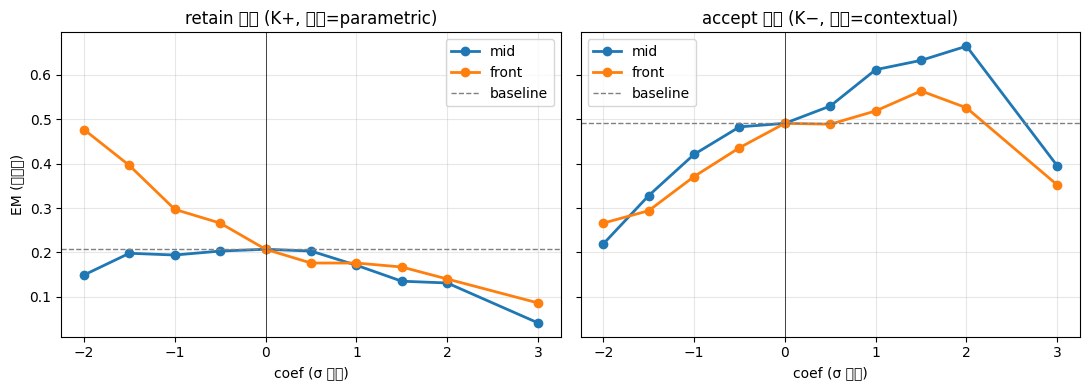

In [ ]:
import matplotlib.pyplot as plt
FINE=[-2,-1.5,-1,-0.5,0,0.5,1,1.5,2,3]
# 위 4개 표의 EM 컬럼을 그대로 붙여넣기
data={
 "retain·mid":  [0.149,0.198,0.194,0.203,0.207,0.203,0.171,0.135,0.131,0.041],
 "retain·front":[0.477,0.396,0.297,0.266,0.207,0.176,0.176,0.167,0.140,0.086],
 "accept·mid":  [0.219,0.328,0.421,0.483,0.491,0.530,0.612,0.633,0.665,0.395],
 "accept·front":[0.266,0.294,0.371,0.436,0.491,0.489,0.519,0.564,0.526,0.352],
}
fig,ax=plt.subplots(1,2,figsize=(11,4),sharey=True)
for k,v in data.items():
    c,b=k.split("·"); a=ax[0] if c=="retain" else ax[1]
    a.plot(FINE,v,marker="o",label=b,lw=2)
for a,t,bl in [(ax[0],"retain 유도 (K+, 정답=parametric)",0.207),(ax[1],"accept 유도 (K−, 정답=contextual)",0.491)]:
    a.axhline(bl,ls="--",c="gray",lw=1,label="baseline"); a.axvline(0,c="k",lw=.5)
    a.set_title(t); a.set_xlabel("coef (σ 단위)"); a.legend(); a.grid(alpha=.3)
ax[0].set_ylabel("EM (정확도)")
plt.tight_layout(); plt.savefig("steering_benchmark.png",dpi=140); plt.show()

In [ ]:
# 훅 완전 제거 상태에서 순수 생성 → coef 0과 비교
for lyr in model.model.layers: lyr._forward_hooks.clear()
print("hooks:", sum(len(l._forward_hooks) for l in model.model.layers))   # 0 확인

def gen_clean(cell, mnt=48):
    gens=[]
    for i in range(0,len(cell),24):
        b=cell.iloc[i:i+24]
        enc=tok([chat(r) for _,r in b.iterrows()],return_tensors="pt",padding=True).to("cuda")
        with torch.no_grad():
            out=model.generate(**enc,max_new_tokens=mnt,do_sample=False,pad_token_id=tok.pad_token_id)
        gens+=tok.batch_decode(out[:,enc.input_ids.shape[1]:],skip_special_tokens=True)
    return gens

def em_of(cell, gens):
    para=cell.parametric_answer.values; ctx=cell.contextual_answer.values; goal=cell.goal.values
    em=col=0
    for t,p,x,g in zip(gens,para,ctx,goal):
        if collapsed(t): col+=1; continue
        hp,hx=find_num(t,p),find_num(t,x)
        if hp and not hx and g=="reject": em+=1
        elif hx and not hp and g=="accept": em+=1
    n=len(cell); return round(em/n,3), round(col/n,3)

for tag,cell in [("reject∩K+",eval_cell),("accept∩K-",acc_cell)]:
    g=gen_clean(cell)
    print(f"{tag:12s} 훅없음 EM={em_of(cell,g)}")

hooks: 0
reject∩K+    훅없음 EM=(0.207, 0.0)
accept∩K-    훅없음 EM=(0.491, 0.0)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, glob
# 백업 경로 후보 자동 탐색
cands = glob.glob('/content/drive/MyDrive/**/hidden_neutral_v2.npy', recursive=True)
print("찾음:", cands)

Mounted at /content/drive
찾음: ['/content/drive/MyDrive/hidden_neutral_v2.npy']


In [ ]:
Hn = np.load(cands[0])      # 여러 개면 맞는 거 골라
print("shape:", Hn.shape, "| size 정합:", Hn.shape[0]*Hn.shape[-1] if Hn.ndim>1 else Hn.size)

shape: (1916, 131072) | size 정합: 251133952


In [ ]:
import numpy as np
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# 로컬 갱신(다음에 안 헤매게)
np.save("hidden_neutral_v2.npy", Hn)

# meta와 정렬: Hn은 sample_id 순서 가정. meta 인덱스가 그 순서인지 K± AUROC로 간접검증
assert len(Hn)==len(meta), f"길이 불일치 {len(Hn)} vs {len(meta)}"
yk = (meta["K"].values=="K+").astype(int)     # 1=K+
grp = meta["question"].values

# K± probe: 레이어별 AUROC (neutral hidden)
def layer_slice(L): return Hn[:, L*4096:(L+1)*4096]
best=None
for L in [14,15,16,17,18,20]:
    X=layer_slice(L)
    oof=cross_val_predict(LogisticRegression(max_iter=1000,C=0.5),X,yk,
                          groups=grp,cv=GroupKFold(5),method="decision_function")
    auc=roc_auc_score(yk,oof)
    print(f"K± probe L{L}: AUROC {auc:.3f}")
    if best is None or auc>best[1]: best=(L,auc)
print("best:", best)

K± probe L14: AUROC 0.778
K± probe L15: AUROC 0.775
K± probe L16: AUROC 0.772
K± probe L17: AUROC 0.776
K± probe L18: AUROC 0.773
K± probe L20: AUROC 0.782
best: (20, np.float64(0.7817218502632771))


In [ ]:
import numpy as np, pandas as pd, torch
from sklearn.linear_model import LogisticRegression

ROUTE_L = 20   # router 레이어

# 평가 혼합 셀
mix = pd.concat([eval_cell.assign(cell="rej_Kp"), acc_cell.assign(cell="acc_Km")]).reset_index(drop=True)
mix_ids = set(mix.sample_id)
print("혼합 셀:", len(mix), "| K+ 실제:", (mix.K=="K+").sum(), "K-:", (mix.K=="K-").sum())

# router 학습: 평가셀 제외한 strat_v2로
Xr = Hn[:, ROUTE_L*4096:(ROUTE_L+1)*4096]
train = ~meta.sample_id.isin(mix_ids).values
clf = LogisticRegression(max_iter=1000, C=0.5).fit(Xr[train], (meta.K.values[train]=="K+").astype(int))

# 평가셀 각 행의 K± 예측 (meta 행 위치로 인덱싱)
pos = meta.reset_index().set_index("sample_id")["index"]
mix_rowidx = mix.sample_id.map(pos).values
pred_Kp = clf.predict(Xr[mix_rowidx]).astype(bool)   # True=K+ 예측
print("router K+ 예측:", pred_Kp.sum(), "/ 실제 K+:", (mix.K=="K+").sum(),
      "| 라우팅 정확도:", round(((mix.K=="K+").values==pred_Kp).mean(),3))

# --- 생성 헬퍼: 행별로 (블록,coef) 다르게 밀어야 해서 그룹으로 처리 ---
def gen_group(rows, blk, Vd, coef, mnt=48):
    attach_block(blk, Vd); _coef["v"]=coef; g=[]
    for i in range(0,len(rows),24):
        b=rows.iloc[i:i+24]
        enc=tok([chat(r) for _,r in b.iterrows()],return_tensors="pt",padding=True).to("cuda")
        with torch.no_grad():
            out=model.generate(**enc,max_new_tokens=mnt,do_sample=False,pad_token_id=tok.pad_token_id)
        g+=tok.batch_decode(out[:,enc.input_ids.shape[1]:],skip_special_tokens=True)
    _coef["v"]=0.0; detach_all(); return g

def em_rows(rows, gens):
    em=0
    for (_,r),t in zip(rows.iterrows(),gens):
        if collapsed(t): continue
        hp,hx=find_num(t,str(r.parametric_answer)),find_num(t,str(r.contextual_answer))
        if hp and not hx and r.goal=="reject": em+=1
        elif hx and not hp and r.goal=="accept": em+=1
    return em

FRONT=[8,9,10,11,12]; MID=[14,15,16,17,18]

def run(route_Kp, label):
    # route_Kp[i]=True면 그 행을 retain/front(-2), False면 accept/mid(+2)
    kp_rows = mix[route_Kp]; km_rows = mix[~route_Kp]
    g_kp = gen_group(kp_rows, FRONT, V_FRONT, -2.0)   # K+로 라우팅 → retain/front
    g_km = gen_group(km_rows, MID,   V_MID,   +2.0)   # K-로 라우팅 → accept/mid
    em = em_rows(kp_rows,g_kp)+em_rows(km_rows,g_km)
    print(f"{label:10s} EM = {em}/{len(mix)} = {em/len(mix):.3f}")
    return em/len(mix)

# 하한: no-steering
for lyr in model.model.layers: lyr._forward_hooks.clear()
g0=gen_clean(mix); base=em_rows(mix,g0)/len(mix)
print(f"{'no-steer':10s} EM = {base:.3f}")

# oracle: 실제 K±대로
run((mix.K=="K+").values, "oracle")
# router: 예측 K±대로
run(pred_Kp, "router")

혼합 셀: 688 | K+ 실제: 222 K-: 466
router K+ 예측: 457 / 실제 K+: 222 | 라우팅 정확도: 0.033
no-steer   EM = 0.395
oracle     EM = 416/688 = 0.605
router     EM = 158/688 = 0.230


0.22965116279069767

In [ ]:
# 1) meta 인덱스가 0..N-1 위치와 일치하나?
print("meta.index 연속?", (meta.index==np.arange(len(meta))).all())

# 2) pos 매핑이 위치를 주는지 라벨로 검증: mix의 실제 K와 Xr 인덱싱한 예측 비교
pos = pd.Series(np.arange(len(meta)), index=meta.sample_id.values)   # 위치 기반으로 재정의
mix_rowidx = mix.sample_id.map(pos).values
print("rowidx NaN:", pd.isna(mix_rowidx).sum())

# 3) 정합성: Xr[mix_rowidx]로 예측한 K+와 mix의 실제 K 비교
pred = clf.predict(Xr[mix_rowidx.astype(int)]).astype(bool)
print("라우팅 정확도(수정):", round(((mix.K=="K+").values==pred).mean(),3))

# 4) 혹시 여전히 낮으면 부호 확인: probe raw score 방향
score = clf.decision_function(Xr[mix_rowidx.astype(int)])
from sklearn.metrics import roc_auc_score
print("mix에서 K± AUROC:", round(roc_auc_score((mix.K=="K+").astype(int), score),3))

meta.index 연속? True
rowidx NaN: 0
라우팅 정확도(수정): 0.033
mix에서 K± AUROC: 0.003


In [ ]:
# hidden_neutral_v2를 만든 원본 순서 후보들과 대조.
# 가장 흔한 케이스: strat_v2_behavior.parquet를 저장 당시 순서 그대로 뽑음.
# → meta가 이미 그 parquet면 순서 같아야 하는데 AUROC 0.003이니 아님.

# 후보 A: sample_id 정렬 순서로 뽑았나?
order_sorted = meta.sort_values("sample_id").index.values
Xr_test = Hn[:, 20*4096:21*4096]
yk_sorted = (meta.sort_values("sample_id").K.values=="K+").astype(int)
from sklearn.model_selection import cross_val_predict, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
oof=cross_val_predict(LogisticRegression(max_iter=1000,C=0.5),Xr_test,yk_sorted,
    groups=meta.sort_values("sample_id").question.values,cv=GroupKFold(5),method="decision_function")
print("sample_id 정렬 가정 AUROC:", round(roc_auc_score(yk_sorted,oof),3))

sample_id 정렬 가정 AUROC: 0.525


In [ ]:
import glob
# 드라이브+런타임에서 id/index 후보 전부 탐색
c = (glob.glob('/content/drive/MyDrive/**/*hidden_neutral*', recursive=True)
   + glob.glob('/content/drive/MyDrive/**/*id*.npy', recursive=True)
   + glob.glob('/content/drive/MyDrive/**/*id*.csv', recursive=True)
   + glob.glob('*.npy')+glob.glob('*id*'))
for p in sorted(set(c)): print(p)

/content/drive/MyDrive/AI_Project/checkpoints/history_small_resnet_wider_aug.csv
/content/drive/MyDrive/hidden_neutral_v2.npy
/content/drive/MyDrive/hidden_neutral_v2_ids.npy
/content/drive/MyDrive/졸프 공유/실험 데이터 공유/P6/hidden_features.npy
/content/drive/MyDrive/졸프 공유/실험 데이터 공유/P6/hidden_sample_ids.npy
hidden_neutral_v2.npy


In [ ]:
import numpy as np, pandas as pd
ids = np.load('/content/drive/MyDrive/hidden_neutral_v2_ids.npy', allow_pickle=True)
print("ids[:3]:", ids[:3], "| len:", len(ids), "| Hn:", len(Hn))

# Hn 행 i ↔ sample_id ids[i]. 이걸 meta 순서로 재배열하는 매핑
id2row = {sid:i for i,sid in enumerate(ids)}
# meta의 각 sample_id가 Hn 몇 번 행인지
meta_to_hn = meta.sample_id.map(id2row)
print("매핑 실패(NaN):", meta_to_hn.isna().sum())      # 0이어야

# Hn을 meta 순서로 재정렬
Hn_aligned = Hn[meta_to_hn.values.astype(int)]

# ★ 진짜 검증: 재정렬된 Hn으로 K± AUROC
from sklearn.model_selection import cross_val_predict, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
X20 = Hn_aligned[:, 20*4096:21*4096]
yk = (meta.K.values=="K+").astype(int)
oof=cross_val_predict(LogisticRegression(max_iter=1000,C=0.5),X20,yk,
    groups=meta.question.values,cv=GroupKFold(5),method="decision_function")
print("정렬 후 K± AUROC:", round(roc_auc_score(yk,oof),3))

ids[:3]: ['clasheval_1902' 'clasheval_2491' 'clasheval_1258'] | len: 1916 | Hn: 1916
매핑 실패(NaN): 0
정렬 후 K± AUROC: 0.782


In [ ]:
import numpy as np, pandas as pd, torch
from sklearn.linear_model import LogisticRegression

ROUTE_L=20
mix = pd.concat([eval_cell.assign(cell="rej_Kp"), acc_cell.assign(cell="acc_Km")]).reset_index(drop=True)
mix_ids=set(mix.sample_id)

Xr = Hn_aligned[:, ROUTE_L*4096:(ROUTE_L+1)*4096]      # ★ 정렬본
train = ~meta.sample_id.isin(mix_ids).values
clf = LogisticRegression(max_iter=1000,C=0.5).fit(Xr[train],(meta.K.values[train]=="K+").astype(int))

pos = pd.Series(np.arange(len(meta)), index=meta.sample_id.values)
ridx = mix.sample_id.map(pos).values.astype(int)
pred_Kp = clf.predict(Xr[ridx]).astype(bool)
print("라우팅 정확도:", round(((mix.K=="K+").values==pred_Kp).mean(),3),
      "| K+예측:",pred_Kp.sum(),"실제:",(mix.K=="K+").sum())

FRONT=[8,9,10,11,12]; MID=[14,15,16,17,18]
def gen_group(rows,blk,Vd,coef,mnt=48):
    attach_block(blk,Vd); _coef["v"]=coef; g=[]
    for i in range(0,len(rows),24):
        b=rows.iloc[i:i+24]
        enc=tok([chat(r) for _,r in b.iterrows()],return_tensors="pt",padding=True).to("cuda")
        with torch.no_grad():
            out=model.generate(**enc,max_new_tokens=mnt,do_sample=False,pad_token_id=tok.pad_token_id)
        g+=tok.batch_decode(out[:,enc.input_ids.shape[1]:],skip_special_tokens=True)
    _coef["v"]=0.0; detach_all(); return g
def em_rows(rows,gens):
    em=0
    for (_,r),t in zip(rows.iterrows(),gens):
        if collapsed(t): continue
        hp,hx=find_num(t,str(r.parametric_answer)),find_num(t,str(r.contextual_answer))
        if hp and not hx and r.goal=="reject": em+=1
        elif hx and not hp and r.goal=="accept": em+=1
    return em
def run(route_Kp,label):
    kp,km=mix[route_Kp],mix[~route_Kp]
    e=em_rows(kp,gen_group(kp,FRONT,V_FRONT,-2.0))+em_rows(km,gen_group(km,MID,V_MID,+2.0))
    print(f"{label:10s} EM = {e}/{len(mix)} = {e/len(mix):.3f}"); return e/len(mix)

for lyr in model.model.layers: lyr._forward_hooks.clear()
print(f"{'no-steer':10s} EM = {em_rows(mix,gen_clean(mix))/len(mix):.3f}")
run((mix.K=="K+").values,"oracle")
run(pred_Kp,"router")

라우팅 정확도: 0.033 | K+예측: 457 실제: 222
no-steer   EM = 0.395
oracle     EM = 416/688 = 0.605
router     EM = 158/688 = 0.230


0.22965116279069767

In [ ]:
# 0) Hn_aligned가 진짜 meta순서인지 재확인 (독립 지표)
X20 = Hn_aligned[:, 20*4096:21*4096]
yk_all = (meta.K.values=="K+").astype(int)

# 1) train/test split 인덱싱 확인
mix_ids=set(mix.sample_id)
train = ~meta.sample_id.isin(mix_ids).values
print("train n:", train.sum(), "| test(mix) n:", (~train).sum(), "| mix len:", len(mix))

# 2) clf 학습 후 train 자체 정확도 (0.7+ 나와야 정상)
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression(max_iter=1000,C=0.5).fit(X20[train], yk_all[train])
print("train acc:", round(clf.score(X20[train], yk_all[train]),3))

# 3) mix 행을 X20에서 뽑는 두 경로가 같은가?
#    경로A: meta 위치 매핑
pos = pd.Series(np.arange(len(meta)), index=meta.sample_id.values)
ridx = mix.sample_id.map(pos).values.astype(int)
#    경로B: boolean mask 순서 (meta에서 mix에 속한 행을 meta 순서로)
maskB = meta.sample_id.isin(mix_ids).values
print("경로A idx[:5]:", ridx[:5])
print("경로B idx[:5]:", np.where(maskB)[0][:5])

# 4) 경로A로 뽑은 특징의 실제 K와, mix.K가 일치하나? ★핵심
kA = yk_all[ridx]                       # X20[ridx]에 대응하는 meta의 K
kMix = (mix.K=="K+").astype(int).values # mix가 들고있는 K
print("경로A K == mix K :", (kA==kMix).mean())   # 1.0이어야 정상

# 5) 예측
pred = clf.predict(X20[ridx])
print("router acc vs mix.K:", round((pred==kMix).mean(),3))
print("router acc vs metaK[ridx]:", round((pred==kA).mean(),3))

train n: 1228 | test(mix) n: 688 | mix len: 688
train acc: 0.988
경로A idx[:5]: [0 1 2 3 4]
경로B idx[:5]: [0 1 2 3 4]
경로A K == mix K : 1.0
router acc vs mix.K: 0.033
router acc vs metaK[ridx]: 0.033


In [ ]:
# 1) 부호 반전 확인: AUROC
from sklearn.metrics import roc_auc_score
score = clf.decision_function(X20[ridx])
print("mix AUROC:", round(roc_auc_score(kMix, score),3))   # <0.5면 반전

# 2) mix 안에서만 GroupKFold CV (올바른 평가: mix 분포에서 K±가 되나)
from sklearn.model_selection import cross_val_predict, GroupKFold
oof = cross_val_predict(LogisticRegression(max_iter=1000,C=0.5),
        X20[ridx], kMix, groups=mix.question.values,
        cv=GroupKFold(5), method="decision_function")
print("mix 내부 CV AUROC:", round(roc_auc_score(kMix, oof),3))

# 3) probe가 K±가 아니라 dataset을 학습했나 확인
ds = mix.dataset_id.values
print("dataset 분포:", pd.Series(ds).value_counts().to_dict())
print("K+ ↔ dataset:", pd.crosstab(mix.K, mix.dataset_id).to_dict())

mix AUROC: 0.003
mix 내부 CV AUROC: 1.0
dataset 분포: {'confiqa_qa': 236, 'nqswap': 230, 'clasheval': 222}
K+ ↔ dataset: {'clasheval': {'K+': 222, 'K-': 0}, 'confiqa_qa': {'K+': 0, 'K-': 236}, 'nqswap': {'K+': 0, 'K-': 230}}
